# Custom pulse shapes

Define an optical pulse with `helios.SampledPulse`, then pass it to `FullWaveformSettings(pulse_shape="sampled", sampled_pulse=...)`.

This example shows the supplied coordinates and the peak-centered runtime shape, handles an ambiguous maximum, saves the settings, and runs a small ground-plane scan.


In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import numpy as np
import matplotlib.pyplot as plt
import helios

# Support launching from the repository root or example_notebooks/.
repo = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (repo / "data/sceneparts/basic/groundplane/groundplane.obj").exists()
helios.add_asset_directory(repo / "data")

## Define the pulse

High-level numeric time coordinates use **seconds**. Strings such as `"2 ns"` also work. Coordinates must be finite and strictly increasing. Nonuniform spacing is supported. Supply at least two samples with nonnegative finite amplitudes and a positive maximum.

Amplitudes are normalized to one. They describe the shape, not absolute transmitted power. Evaluation interpolates linearly and is zero outside the supplied support. The samples determine the pulse width. The scanner's analytic-pulse FWHM does not rescale this custom shape.

In [2]:
pulse = helios.SampledPulse(
    offsets=["0 ns", "1 ns", "2 ns", "4 ns", "7 ns", "10 ns"],
    amplitudes=[0, 1, 4, 2, 0.5, 0],
)
settings = helios.FullWaveformSettings(
    pulse_shape="sampled",
    sampled_pulse=pulse,
    sample_spacing="2 cm",
    peak_window="10 cm",
)
print("Original offsets [s]:", pulse.offsets)
print("Normalized amplitudes:", pulse.amplitudes)
print("Explicit peak selector:", pulse.peak_offset)  # None: infer unique maximum

Original offsets [s]: (0.0, 1e-09, 2e-09, 4e-09, 7.000000000000001e-09, 1e-08)
Normalized amplitudes: (0.0, 0.25, 1.0, 0.5, 0.125, 0.0)
Explicit peak selector: None


## Inspect automatic peak centering

The input maximum is at 2 ns. HELIOS subtracts this coordinate internally, so the runtime maximum is at zero. Original coordinates remain available for inspection and serialization. `pulse.peak_offset` remains `None` when the selector was omitted.

The following uses the low-level scanner interface to inspect the prepared model. Its `evaluate` and `recording_bounds` use **range-equivalent metres**, with `range_offset = time_offset * c / 2`. The factor two accounts for round-trip travel. The low-level `_helios.SampledPulse` constructor instead accepts input nanoseconds. Use the high-level interface above for ordinary configuration.

Centered support [m]: (-0.299792458, 1.199169832)


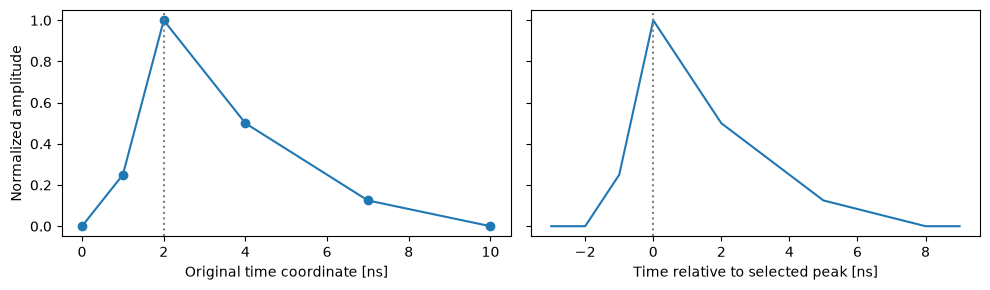

In [10]:
# Create the scanner
scanner = helios.scanner_from_name("riegl_vz_400")

# Convert the Python waveform settings into their C++ representation and assign them to scanner channel 0
scanner._cpp_object.set_fwf_settings(settings._to_cpp(), 0)

# Prepare the channel's runtime pulse model
scanner._cpp_object.prepare_pulse(0)

# Retrieve the model so we can evaluate and plot it
model = scanner._cpp_object.get_pulse_model(0)

c = 299792458.0
input_ns = np.asarray(pulse.offsets) * 1e9
relative_ns = np.linspace(-3, 9, 601)
runtime_values = np.array([model.evaluate(t * 1e-9 * c / 2) for t in relative_ns])
assert model.evaluate(0) == 1
print("Centered support [m]:", model.recording_bounds)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
axes[0].plot(input_ns, pulse.amplitudes, "o-")
axes[0].axvline(2, color="grey", linestyle=":")
axes[0].set(xlabel="Original time coordinate [ns]", ylabel="Normalized amplitude")
axes[1].plot(relative_ns, runtime_values)
axes[1].axvline(0, color="grey", linestyle=":")
axes[1].set(xlabel="Time relative to selected peak [ns]")
fig.tight_layout()
plt.show()

## Select a maximum explicitly

For a unique maximum, omit `peak_offset`. For tied maxima or a plateau, supply a coordinate at a maximum of the interpolated shape. It selects the reference before centering.

For the plateau below, any coordinate from 1 to 3 ns is valid. Choosing its midpoint puts that midpoint at runtime zero. A maximum detector can still choose a different point on the plateau: centering does not resolve detector tie-breaking.

Pulse definitions are immutable. To change a shape, create a new `SampledPulse` and replace `settings.sampled_pulse` before running the survey.

In [11]:
plateau = helios.SampledPulse(
    offsets=["0 ns", "1 ns", "3 ns", "5 ns"],
    amplitudes=[0, 2, 2, 0],
    peak_offset="2 ns",
)
assert plateau.peak_offset == 2e-9

try:
    helios.SampledPulse(
        offsets=["0 ns", "1 ns", "3 ns", "5 ns"],
        amplitudes=[0, 2, 2, 0],
        peak_offset="0 ns",
    )
except ValueError as error:
    print("Invalid selector rejected:", error)

Invalid selector rejected: Explicit peak offset must lie at a pulse maximum


## Save and restore the definition

YAML preserves the original coordinates and optional selector. Restoring or preparing the settings repeatedly does not accumulate shifts. Custom sampled definitions are supported through Python and YAML, not scanner XML.

In [12]:
with TemporaryDirectory() as directory:
    path = settings.to_yaml(Path(directory) / "custom-pulse.yaml")
    restored = helios.FullWaveformSettings.from_yaml(path)
    assert restored.sampled_pulse.offsets == pulse.offsets
    assert restored.sampled_pulse.amplitudes == pulse.amplitudes
    assert restored.sampled_pulse.peak_offset is None
    print(path.read_text())

# yaml-language-server: $schema=https://raw.githubusercontent.com/3dgeo-heidelberg/helios/main/python/helios/data/serialization_schema.json
serialization_major_version: 1
serialization_minor_version: 0
model_class: helios.settings.FullWaveformSettings
fields:
  sample_spacing: 0.02
  beam_sampling_method: annular
  beam_sample_quality: 3
  beam_sampling_factor: 2.0
  peak_window: 0.1
  max_recording_span: 0.0
  pulse_shape: sampled
  sampled_pulse:
    serialization_major_version: 1
    serialization_minor_version: 0
    model_class: helios.settings.SampledPulse
    fields:
      offsets:
      - 0.0
      - 1.0e-09
      - 2.0e-09
      - 4.0e-09
      - 7.000000000000001e-09
      - 1.0e-08
      amplitudes:
      - 0.0
      - 0.25
      - 1.0
      - 0.5
      - 0.125
      - 0.0
      peak_offset: null
  recording_tail_tolerance: 0.0001



## Use the shape in a survey: a small downward-looking scan of a ground plane

For an existing survey, assign `survey.full_waveform_settings = settings` before `survey.run()`. The settings can also be passed to the survey constructor.

The returned point ranges and full-waveform sample coordinates share the same peak reference. No additional pulse-offset subtraction is needed. Measurement noise, overlapping returns, and different detection rules can still change the detected range.

In [13]:
ground = helios.ScenePart.from_obj(
    "sceneparts/basic/groundplane/groundplane.obj"
).scale(100)

survey = helios.Survey(
    scanner=scanner,
    platform=helios.platform_from_name("tripod"),
    scene=helios.StaticScene(scene_parts=[ground]),
    full_waveform_settings=settings,
)

survey.add_leg(
    scanner_settings=helios.ScannerSettings(
        pulse_frequency="100000 Hz",
        vertical_resolution="0.2 deg",
        horizontal_resolution="1 deg",
        min_vertical_angle="-40 deg",
        max_vertical_angle="-10 deg",
    ),
    x=0,
    y=0,
    z=2,
    rotation_start_angle="0 deg",
    rotation_stop_angle="10 deg",
)

with TemporaryDirectory() as output_dir:
    points, trajectories = survey.run(
        format=helios.OutputFormat.NPY,
        output_dir=output_dir,
        num_threads=1,
        kdt_num_threads=1,
        kdt_geom_num_threads=1,
        progressbar="none",
    )

assert len(points) > 0
assert survey.scanner._cpp_object.get_pulse_model().evaluate(0) == 1

print(f"Returned {len(points)} points")
print("First ranges [m]:", points["distance"][:5])

2026-11-16 13:59:02 +0100 | WARNING | 5164409513072196502 |/home/thomas/repositories/helios/src/assetloading/SpectralLibrary.cpp:131 | helios | Warning: material None of primitive 8Triangle (/home/thomas/repositories/helios/data/sceneparts/basic/groundplane/groundplane.mtl) has no spectral definition
Returned 2003 points
First ranges [m]: [5.77172275 5.80145745 5.82847885 5.84872716 5.88377255]
